# RQ3: Genre popularity: rainiest vs driest months

**Question:** Which music genres become more or less popular in the rainiest months in Germany compared to the driest months?

This notebook is a **reporting layer**: it reads the outputs produced by the `Workflow 3` Snakemake pipeline and adds interpretation. It does **not** recompute anything; the analysis lives in the tested CLI component `src/Workflow 3/genre_shift.py`.

## Method (in brief)

1. Rank every calendar month (2017–2021) by mean daily precipitation, and take the `n_months` rainiest and `n_months` driest.
2. Within each group, compute each genre's **stream share** (% of the group's streams) and **count share** (% of charting song-rows).
3. Report the **shift** = rainy share − dry share. Positive ⇒ relatively more popular in rainy months.

## How to reproduce

```bash
cd "src/Workflow 3"
snakemake -s SnakefileWorkflow3 --cores 1
```

This regenerates `results/workflow_3/genre_shift.csv` and `genre_shift.png`, which the cells below load.

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import Image, display

RESULTS = Path("..") / "results" / "workflow_3"
shift = pd.read_csv(RESULTS / "genre_shift.csv", index_col=0)
print(f"{len(shift)} genres in the shift table")
shift.head(10)

68 genres in the shift table


,rainy_stream_share,dry_stream_share,stream_shift,rainy_count_share,dry_count_share,count_shift
indie-pop,0.0780,0.0287,0.0493,0.0578,0.0238,0.0340
pop,0.1286,0.0806,0.0480,0.1175,0.0756,0.0419
hip-hop,0.0965,0.0746,0.0218,0.0768,0.0691,0.0076
edm,0.1943,0.1748,0.0195,0.1831,0.1710,0.0121
french,0.0149,0.0043,0.0105,0.0127,0.0057,0.0070
alternative,0.0214,0.0139,0.0075,0.0350,0.0243,0.0107
piano,0.0101,0.0035,0.0066,0.0092,0.0046,0.0046
latino,0.0079,0.0015,0.0065,0.0123,0.0021,0.0102
show-tunes,0.0076,0.0025,0.0051,0.0108,0.0037,0.0071
k-pop,0.0051,0.0023,0.0028,0.0069,0.0034,0.0035


In [2]:
cols = ["rainy_stream_share", "dry_stream_share", "stream_shift"]

print("More popular in RAINY months:")
display(shift.sort_values("stream_shift", ascending=False).head(5)[cols])

print("More popular in DRY months:")
display(shift.sort_values("stream_shift").head(5)[cols])

More popular in RAINY months:


,rainy_stream_share,dry_stream_share,stream_shift
indie-pop,0.0780,0.0287,0.0493
pop,0.1286,0.0806,0.0480
hip-hop,0.0965,0.0746,0.0218
edm,0.1943,0.1748,0.0195
french,0.0149,0.0043,0.0105


More popular in DRY months:


,rainy_stream_share,dry_stream_share,stream_shift
dance,0.1655,0.2396,-0.0741
electro,0.0319,0.0625,-0.0306
rock,0.0141,0.0304,-0.0163
latin,0.0148,0.0279,-0.0131
emo,0.0120,0.0247,-0.0127


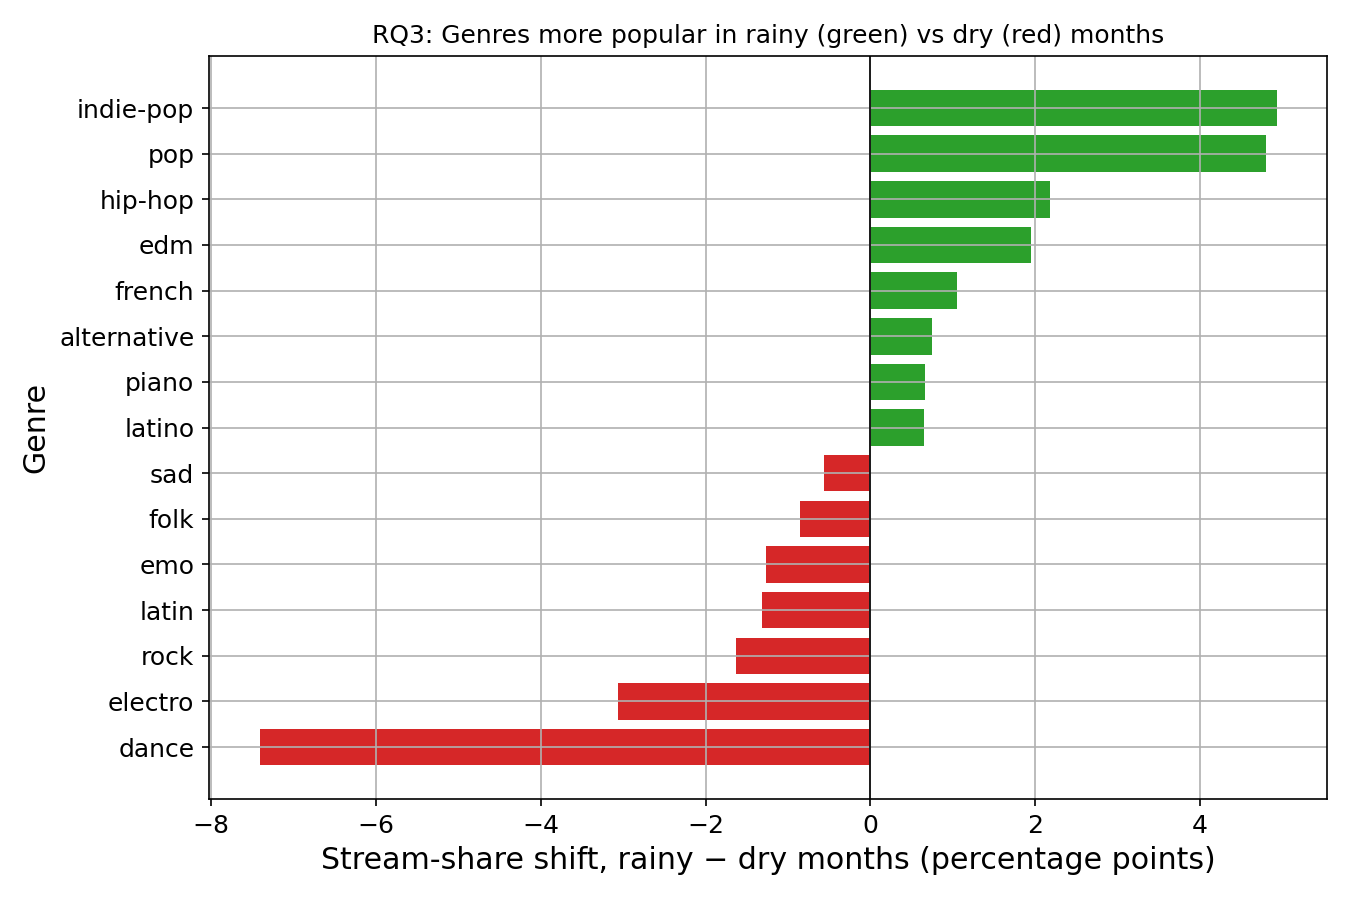

In [3]:
display(Image(filename=str(RESULTS / "genre_shift.png")))

## Findings

- **Rainy months favour vocal, song-driven genres.** *indie-pop* (+4.9 pp) and *pop* (+4.8 pp) gain the most stream share, followed by *hip-hop* (+2.2 pp) and *edm* (+1.9 pp).
- **Dry months favour dance/electronic and guitar music.** *dance* moves by far the most (−7.4 pp, i.e. much more popular in dry months), with *electro* (−3.1 pp), *rock* (−1.6 pp), and *latin*/*emo* also higher when it is dry.
- **One genre dominates the signal:** the *dance* shift (~7 pp) is roughly 50% larger than the next-biggest mover; every other genre sits within about ±5 pp, so most shifts are modest.
- **The electronic family splits**: one strange finding is that *edm* rises in rainy months while *dance*/*electro* rise in dry months; so this is *not* a clean "electronic = dry" story.
- **Both metrics agree.** We headline `stream_shift` (weighted by actual listening volume); the `count_shift` column (share of charting entries) points the same direction for the top movers (e.g. indie-pop +3.4 pp, pop +4.2 pp by count), so the pattern is not just an artefact of a few heavily-streamed hits.

Overall: 
- drier months bring warmer, more outdoor and social listening, which fits the upbeat, high-energy *dance/electro* lift
- wetter months tilt toward indoor, vocal, song-led *indie-pop/pop*. 

However, we need to consider the the caveats below this is at least as much a **seasonal** pattern as a weather one.

## Caveats

- **Genre coverage:** genre labels exist only for the ~22% of charting songs that matched the audio-features dataset, and that subset is skewed toward electronic genres. Read results as relative shifts *within this sample*, not absolute national genre popularity.
- **Confounds:** the 2017–2021 window includes COVID-19 and seasonal cultural events (Christmas, etc.) that correlate with both weather and listening; rainy/dry months are not randomly assigned.
- **Granularity:** months are ranked by mean precipitation, so within-month variation is averaged out.

## Takeaway

Precipitation is associated with a measurable shift in the genre mix of the German charts: most clearly a swing between *dance/electro* (drier months) and *indie-pop/pop* (wetter months), with *dance* the single largest mover, and with stream-share and count-share pointing the same way. But because the driest months are largely summer months, the effect is strongly confounded with **season**, so we read it as a *descriptive association* rather than evidence that rain itself changes what people stream. Apart from *dance* (~7 pp), the shifts are small (a few percentage points).